# Seismic inversion of a synthetic sand wedge, step by step

This notebook runs **pydelivery** (the Python port of CSIRO's Delivery) on a
small made-up example where we know the right answer.

The plan:

1. Invent a simple earth: a sand layer between two shales. The sand is thick
   on the left and thins to nothing (a **wedge**). It is filled with **gas**.
2. Make the seismic that this earth would produce, plus some noise.
3. Forget the truth. Give the inversion only the seismic and what an
   interpreter would roughly know beforehand (the *prior*).
4. Run the inversion. It returns many plausible earth models (*samples*)
   that fit the seismic and the prior.
5. Compare the answers with the truth, including the standard QC display:
   true impedance, input seismic, estimated impedance, synthetic from the
   estimate, and the residual.

Two questions make Delivery different from most inversions, and we will see
both answered:

* **Is the sand there at all, or has it pinched out?**
* **Is it filled with gas or brine?**

Everything runs in plain Python. Data files are written to a `wedge_data`
folder next to this notebook.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import pydelivery
from pydelivery import Inversion, StateModel, enumerate_fluid_states, load_config
from pydelivery.config import apply_prior_trace
from pydelivery.io import TraceSet, write_prior_table, write_traces
from pydelivery.qc import plot_qc, posterior_sections
from pydelivery.seismic import build_seismic_model, load_wavelet

rng = np.random.default_rng(42)          # fixed seed: the notebook gives the same answer every run
work = Path("wedge_data")
work.mkdir(exist_ok=True)
print("pydelivery", pydelivery.__version__)

pydelivery 0.2.0


## Step 1: the wavelet

Seismic is the earth's layering seen through a blurry "lens": the
**wavelet**. Each boundary between layers sends back an echo shaped like the
wavelet, scaled by how different the two layers are.

We use a standard 30 Hz Ricker wavelet, sampled every 4 ms. It is centred on
time zero, so it starts at a negative time.

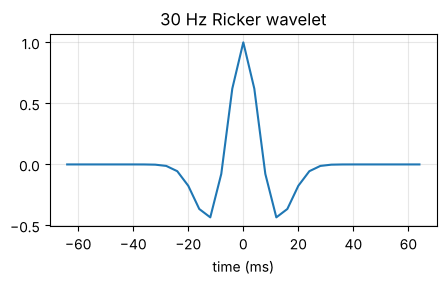

In [2]:
dt = 0.004                                   # sample interval, seconds
f = 30.0                                     # peak frequency, Hz
t_w = np.arange(-16, 17) * dt                # -64 ms ... +64 ms
wavelet = (1 - 2 * (np.pi * f * t_w) ** 2) * np.exp(-(np.pi * f * t_w) ** 2)

# a wavelet file is just one trace whose start time (t0) is negative
write_traces(work / "wavelet.h5", TraceSet(wavelet[None, :], dt, t_w[0]))

plt.figure(figsize=(5, 2.5))
plt.plot(1000 * t_w, wavelet)
plt.xlabel("time (ms)"); plt.title("30 Hz Ricker wavelet"); plt.grid(alpha=0.3)
plt.show()

## Step 2: describe the model in Delivery's XML

Delivery describes the problem in an XML file. Ours has three layers:

| Layer | Rock | What we tell the inversion |
|---|---|---|
| 1. Seal | shale | its top time (picked well, ±5 ms) |
| 2. Reservoir | sand mixed with shale (net-to-gross about 0.8) | its top time ±5 ms; **50 % chance of gas, 50 % brine** |
| 3. Base | shale | its top time (= base of the sand) ±10 ms |

The rock properties come from **trend curves**: rules like "sand velocity is
about 3000 m/s, give or take 150". The fluid properties of brine and gas
are given too. Delivery combines these with **Gassmann's equation** to work
out how gas changes the sand's velocity and density.

With these numbers a brine-filled sand looks almost like the shale around it
(a reflection coefficient of about -0.01: nearly invisible), but gas makes the
sand much softer and lighter (about -0.12): a **bright spot**. That contrast
is what lets the seismic tell gas from brine.

The `varies_areally="true"` flags say that some values change from trace to
trace; we will supply those in a small table in Step 4.

In [3]:
xml = """<?xml version="1.0"?>
<inversion>
  <seismic_data>
    <stack>
      <name>near</name>
      <filename>stack.h5</filename>
      <min_offset>0</min_offset><max_offset>1000</max_offset>
      <reflector_time>1900</reflector_time><stack_velocity>2500</stack_velocity>
      <wavelet><filename>wavelet.h5</filename><noise_rms>0.01</noise_rms></wavelet>
    </stack>
    <AVO_terms><A>1.0</A><B>1.0</B></AVO_terms>
  </seismic_data>

  <model_description>
    <top_layer>
      <name>seal</name>
      <nonreservoir_endmember><name>shale</name></nonreservoir_endmember>
      <time>1800</time><sigma_time>5</sigma_time>
      <net_to_gross>0</net_to_gross>
      <depth>2000</depth><sigma_depth>0</sigma_depth><LFIV>2000</LFIV><sigma_LFIV>0</sigma_LFIV>
    </top_layer>
    <middle_layer>
      <name>reservoir sand</name>
      <reservoir_endmember>
        <name>sand</name>
        <brine><name>brine</name></brine>
        <gas><name>gas</name>
          <probability_of_gas>0.5</probability_of_gas>
          <saturation_of_gas>0.8</saturation_of_gas>
        </gas>
      </reservoir_endmember>
      <nonreservoir_endmember><name>shale</name></nonreservoir_endmember>
      <time varies_areally="true">1900</time><sigma_time>5</sigma_time>
      <net_to_gross>0.8</net_to_gross><sigma_net_to_gross>0.1</sigma_net_to_gross>
      <depth>2000</depth><sigma_depth>0</sigma_depth><LFIV>2000</LFIV><sigma_LFIV>0</sigma_LFIV>
    </middle_layer>
    <bottom_layer>
      <name>base shale</name>
      <nonreservoir_endmember><name>shale</name></nonreservoir_endmember>
      <time varies_areally="true">1940</time><sigma_time>10</sigma_time>
      <net_to_gross>0</net_to_gross>
      <depth>2000</depth><sigma_depth>0</sigma_depth><LFIV>2000</LFIV><sigma_LFIV>0</sigma_LFIV>
      <t_base>2050</t_base><sigma_t_base>5</sigma_t_base>
    </bottom_layer>
  </model_description>

  <rock_fluid_properties>
    <fluid_properties>
      <fluid><name>brine</name><vp>1750</vp><sigma_vp>0</sigma_vp><rho>1050</rho><sigma_rho>0</sigma_rho></fluid>
      <fluid><name>gas</name><vp>550</vp><sigma_vp>50</sigma_vp><rho>150</rho><sigma_rho>30</sigma_rho></fluid>
    </fluid_properties>
    <rock_properties>
      <reservoir_endmember><name>sand</name><reference_fluid>brine</reference_fluid>
        <vp_curve><intercept>3000</intercept><depth_coefficient>0</depth_coefficient>
                  <LFIV_coefficient>0</LFIV_coefficient><sigma>150</sigma></vp_curve>
        <vs_curve><intercept>-733</intercept><slope>0.768</slope><sigma>100</sigma></vs_curve>
        <porosity_curve><intercept>0.655</intercept><slope>-0.0001183</slope><sigma>0.02</sigma></porosity_curve>
        <vp_grain>6110</vp_grain><vs_grain>4131</vs_grain><rho_grain>2649</rho_grain>
      </reservoir_endmember>
      <nonreservoir_endmember><name>shale</name>
        <vp_curve><intercept>2812</intercept><depth_coefficient>0</depth_coefficient>
                  <LFIV_coefficient>0</LFIV_coefficient><sigma>100</sigma></vp_curve>
        <vs_curve><intercept>-496</intercept><slope>0.57</slope><sigma>43</sigma></vs_curve>
        <density_curve><factor>300</factor><exponent>0.26</exponent><sigma>20</sigma></density_curve>
      </nonreservoir_endmember>
    </rock_properties>
  </rock_fluid_properties>

  <output><density_ordering>full</density_ordering></output>
</inversion>
"""
(work / "ModelDescription.xml").write_text(xml)
cfg = load_config(work / "ModelDescription.xml")
print([lay.name for lay in cfg.layers])
print("possible fluid states:", [(s.label, s.probability) for s in enumerate_fluid_states(cfg)])

['seal', 'reservoir sand', 'base shale']
possible fluid states: [('bbb', 0.5), ('bgb', 0.5)]


The fluid states are written one letter per layer: `b` = brine, `g` = gas.
Only the sand can hold gas, so there are two possibilities, `bbb` and `bgb`,
each with prior probability 0.5.

## Step 3: the true earth (which the inversion will not see)

200 traces across the wedge. The sand top is at 1900 ms everywhere. Its
thickness (in two-way time) shrinks from 40 ms on the left to zero at
trace 130; from there on the sand is absent. The sand holds gas.

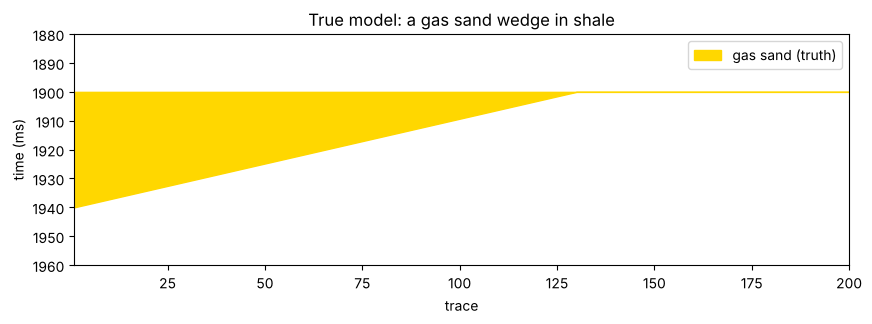

In [4]:
n_traces = 200
x = np.arange(1, n_traces + 1)
top_true = np.full(n_traces, 1.900)                                   # seconds
thick_true = np.clip(0.040 * (1 - (x - 1) / 129), 0, None)            # 40 ms -> 0 at trace 130
base_true = top_true + thick_true

plt.figure(figsize=(10, 3))
plt.fill_between(x, 1000 * top_true, 1000 * base_true, color="gold", label="gas sand (truth)")
plt.gca().invert_yaxis()
plt.xlabel("trace"); plt.ylabel("time (ms)"); plt.xlim(1, n_traces); plt.ylim(1960, 1880)
plt.title("True model: a gas sand wedge in shale"); plt.legend(); plt.show()

## Step 4: what the interpreter knows (the prior table)

Before inverting, an interpreter has picked horizons on the seismic. Picks
are never perfect, so we add a few milliseconds of random error to the true
times. These picks become the **prior means**; the `sigma_time` values in the
XML say how far off they might be.

Where the true sand is absent the base pick sits on (or even above) the top
pick. The inversion has to decide from the seismic whether the sand is really
there.

Per-trace values go in a *prior table*: one named array per XML tag. Times
are in milliseconds, with the bottom of the model (`t_base`) as the last
column. `NaN` means "use the value in the XML".

In [5]:
top_pick = top_true + rng.normal(0, 0.003, n_traces)
base_pick = base_true + rng.normal(0, 0.006, n_traces)

times_table = np.full((n_traces, 4), np.nan)  # columns: seal top, sand top, base-shale top, t_base
times_table[:, 1] = 1000 * top_pick
times_table[:, 2] = 1000 * base_pick
write_prior_table(work / "priors.h5", {"time": times_table})
print("first five traces (ms):\n", np.round(times_table[:5, 1:3], 1))

first five traces (ms):
 [[1900.9 1942. ]
 [1896.9 1948.1]
 [1902.3 1939.9]
 [1902.8 1942.9]
 [1894.1 1926.5]]


## Step 5: make the synthetic seismic

We ask pydelivery's own forward model what seismic the true earth produces.
For each trace:

* take the prior settings for that trace,
* set the layer times to the truth and choose the gas fluid state,
* compute the synthetic trace (reflection coefficients convolved with the
  wavelet) and, for the QC later, the true impedance,
* add random noise at the level stated in the XML (0.01, about a tenth of the
  gas-sand echo).

The seismic is written to `stack.h5`, the file the XML points to.

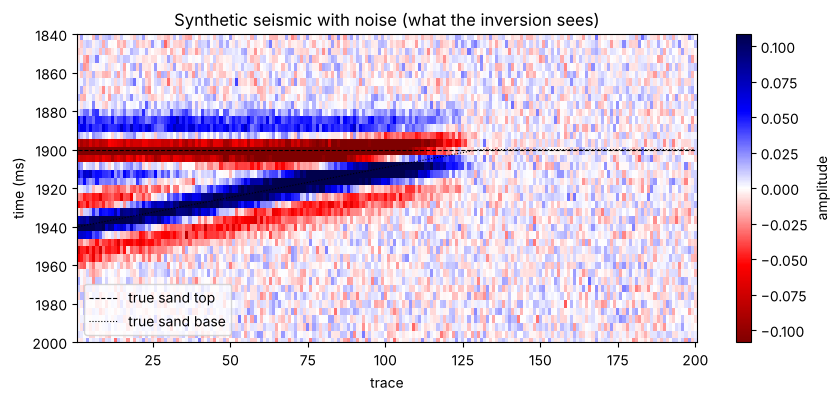

In [6]:
table = {"time": times_table}
w = load_wavelet(work / "wavelet.h5")
t0, ns = 1.700, 150                                   # traces start at 1700 ms, 150 samples
times = t0 + dt * np.arange(ns)                       # the seismic time axis (s)
clean = np.zeros((n_traces, ns))
Z_true = np.zeros((n_traces, ns))
for i in range(n_traces):
    cfg_i = apply_prior_trace(cfg, table, i)
    blank = TraceSet(np.zeros((1, ns)), dt, t0)[0]
    seis = build_seismic_model(cfg_i, [blank], [w])
    gas = next(s for s in enumerate_fluid_states(cfg_i) if s.label == "bgb")
    model = StateModel(cfg_i, gas, seis)
    m = model.prior_mean.copy()                       # typical rock properties ...
    m[model.index[("t", 1)]] = top_true[i]            # ... but the true times
    m[model.index[("t", 2)]] = base_true[i]
    tr = model.time_traces(m[None], times)
    clean[i], Z_true[i] = tr["synthetic_0"][0], tr["Zp"][0]

noise = rng.normal(0, 0.01, clean.shape)
data = clean + noise
write_traces(work / "stack.h5", TraceSet(data, dt, t0))

def section(d, title, cmap="seismic_r", clip=None, label="amplitude"):
    clip = clip or np.percentile(np.abs(d), 99)
    plt.figure(figsize=(10, 4))
    plt.imshow(d.T, aspect="auto", cmap=cmap, vmin=-clip, vmax=clip,
               extent=[0.5, n_traces + 0.5, 1000 * times[-1], 1000 * times[0]])
    plt.colorbar(label=label); plt.ylim(2000, 1840)
    plt.xlabel("trace"); plt.ylabel("time (ms)"); plt.title(title)

section(data, "Synthetic seismic with noise (what the inversion sees)")
plt.plot(x, 1000 * top_true, "k--", lw=0.8, label="true sand top")
plt.plot(x, 1000 * base_true, "k:", lw=0.8, label="true sand base")
plt.legend(loc="lower left"); plt.show()

The gas sand gives a strong trough (red) at its top and a strong peak (blue)
at its base. As the wedge thins the two echoes move together and merge
(*tuning*); beyond trace 130, where the sand is gone, only noise is left.

## Step 6: run the inversion

From here on we use only the files: the XML, the seismic, the wavelet and the
prior table. At each trace pydelivery:

1. lists the possible fluid states (`bbb`, `bgb`),
2. finds the best-fitting models for each (there can be several, e.g. sand
   present or pinched out),
3. runs a Markov chain Monte Carlo sampler that wanders between all of them,
   spending time in each in proportion to how probable it is.

Traces are independent, so they run in parallel on all CPU cores
(`n_jobs=-1`). We take 500 samples per trace; this takes a few minutes.

In [7]:
import time
inv = Inversion.from_files(work / "ModelDescription.xml", work / "priors.h5")
start = time.time()
results = inv.run(n_samples=500, seed=1, n_jobs=-1)
inv.save(work / "results.h5", results)
print(f"{len(results)} traces x {results[0].n_samples} samples in {time.time() - start:.0f} s")

200 traces x 500 samples in 319 s


## Step 7: the standard inversion QC

Five sections, as for any synthetic inversion test:

1. **Input (true) impedance** - the earth we built.
2. **Input seismic** - what the inversion was given.
3. **Estimated impedance** - the posterior mean: at every time sample, the
   average impedance over the 500 samples of that trace. Where the inversion
   is unsure (for example of exactly where a thin layer ends) the average
   blurs; that blur *is* the uncertainty.
4. **Synthetic from the estimate** - the average of the synthetics of all
   samples, which is the wavelet convolved with the average reflectivity.
5. **Residual** - input seismic minus the synthetic. It should look like the
   noise we added: no coherent events left behind.

The bottom-left panel shows one posterior sample per trace, to show that each
individual answer is a sharp, blocky layered model. Impedance panels share one
colour scale, and the three seismic panels share another.

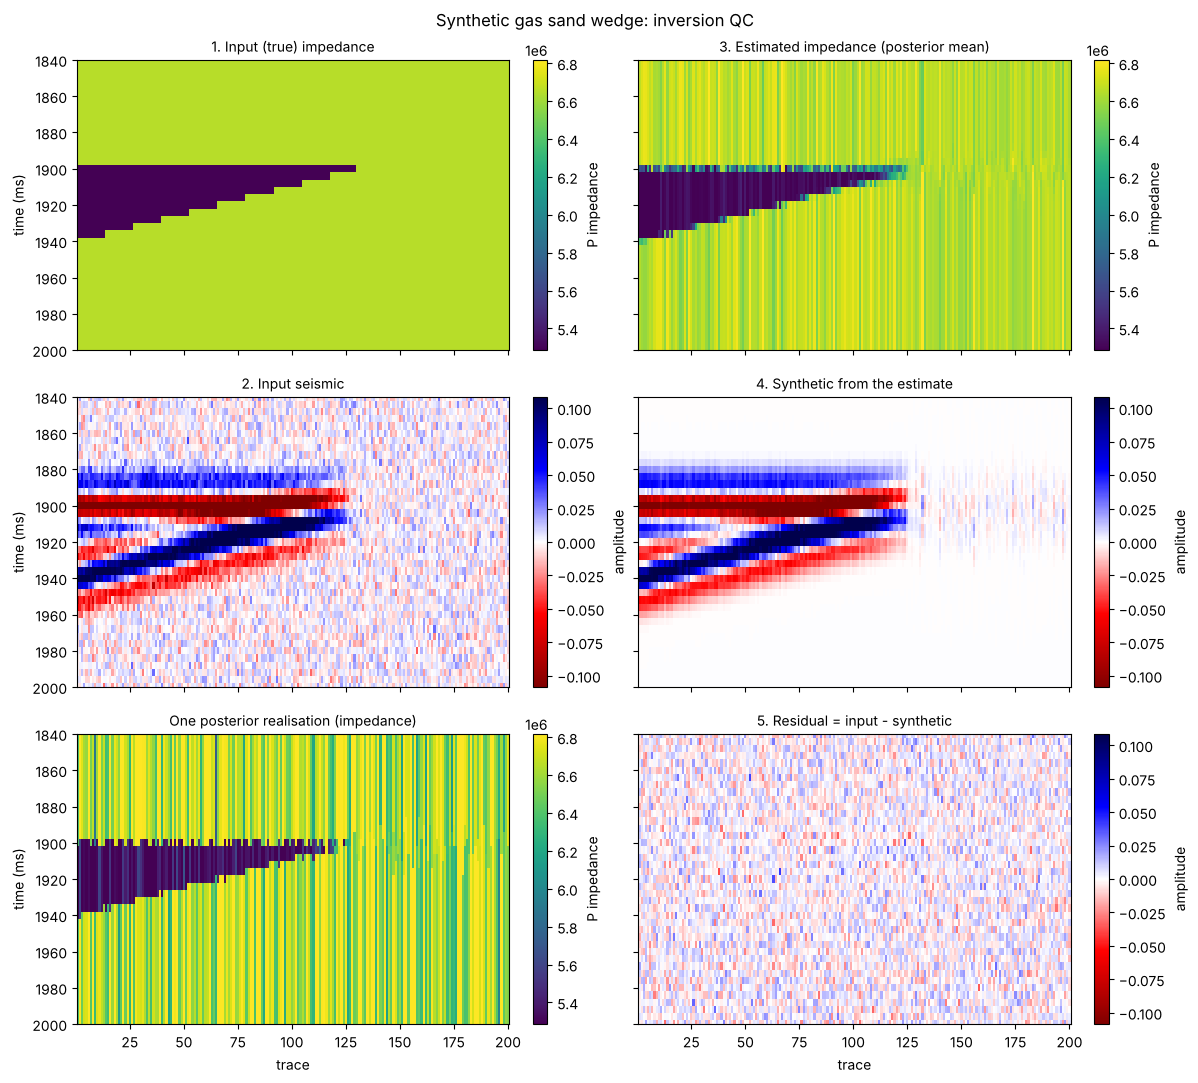

RMS of input seismic: 0.0201
RMS of residual:      0.0100   (noise added: 0.0100)


In [8]:
sec = posterior_sections(results, times)
fig, stats = plot_qc(times, data, Z_true, sec["Zp_mean"], sec["synthetic_mean"],
                     Z_sample=sec["Zp_sample"], time_range=(1.84, 2.0),
                     title="Synthetic gas sand wedge: inversion QC")
plt.show()
print(f"RMS of input seismic: {stats['rms_seismic']:.4f}")
print(f"RMS of residual:      {stats['rms_residual']:.4f}   (noise added: 0.0100)")

How to read it:

* **Estimated vs true impedance (panels 1 and 3):** the low-impedance gas
  sand is recovered with the right top, a base that follows the wedge, and
  nothing beyond trace ~130 where the sand is absent. Near the pinch-out
  (traces ~115-130) the sand fades rather than ending sharply: some samples
  there have no sand at all, and the mean blends them in.
* **Residual (panel 5):** no coherent events remain, and its RMS equals the
  noise we added (0.0100). The inversion has explained all the signal, and
  has not fitted the noise.
* **Vertical striping in the shales (panels 3 and 6):** band-limited seismic
  measures impedance *contrasts*, not absolute levels. The absolute shale
  impedance therefore comes mostly from the rock-trend prior (±100 m/s in
  velocity, ±20 kg/m³ in density), and because each trace is inverted on its
  own, it wanders within that range from trace to trace. A single realisation
  (panel 6) shows this most clearly. Delivery does not impose lateral
  continuity; the contrasts, which the seismic does constrain, are consistent
  from trace to trace.

## Step 8: the questions Delivery is built for

### Is the sand there, and how thick is it?

The orange band is the P10-P90 range of the sand thickness (two-way time)
across the samples, the line is the median and the dashed line is the truth.
Below it, the probability that the sand has pinched out.

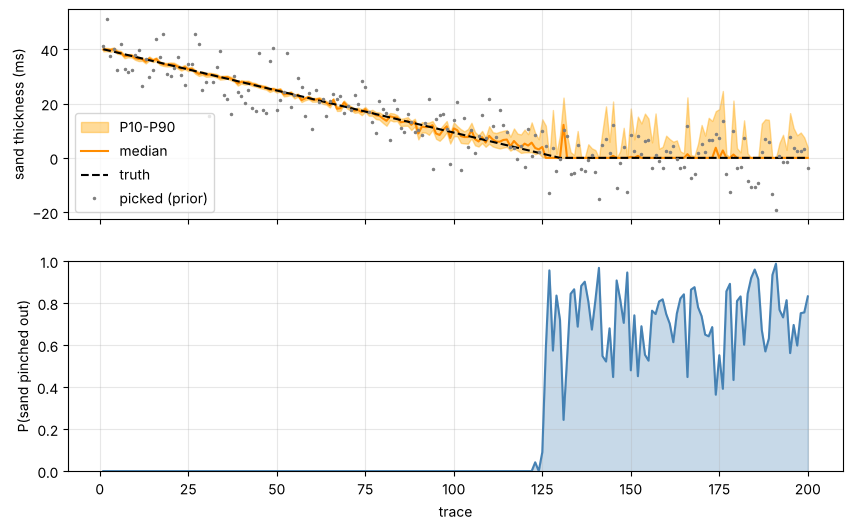

In [9]:
thick = np.array([1000 * (r.samples["t"][:, 2] - r.samples["t"][:, 1]) for r in results])
p10, p50, p90 = np.percentile(thick, [10, 50, 90], axis=1)
pinch = np.array([r.pinchout_probability()[1] for r in results])

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].fill_between(x, p10, p90, color="orange", alpha=0.4, label="P10-P90")
ax[0].plot(x, p50, color="darkorange", label="median")
ax[0].plot(x, 1000 * thick_true, "k--", label="truth")
ax[0].plot(x, times_table[:, 2] - times_table[:, 1], ".", color="gray", ms=3, label="picked (prior)")
ax[0].set_ylabel("sand thickness (ms)"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(x, pinch, color="steelblue")
ax[1].fill_between(x, 0, pinch, color="steelblue", alpha=0.3)
ax[1].set_ylabel("P(sand pinched out)"); ax[1].set_xlabel("trace"); ax[1].set_ylim(0, 1)
ax[1].grid(alpha=0.3); plt.show()

* Where the sand is present (traces 1-129) the median thickness sits on the
  truth, with a narrow range, far tighter than the scattered picks (grey dots)
  it started from. The seismic, not the picks, is setting the answer.
* Where the sand is absent (130-200) the inversion gives a **probability that
  the sand has pinched out**, mostly 60-95 %, and allows a small chance of a
  thin layer (up to 10-20 ms at P90) where the noise could hide one. It does
  not force a yes/no answer or invent a thickness.

### Gas or brine?

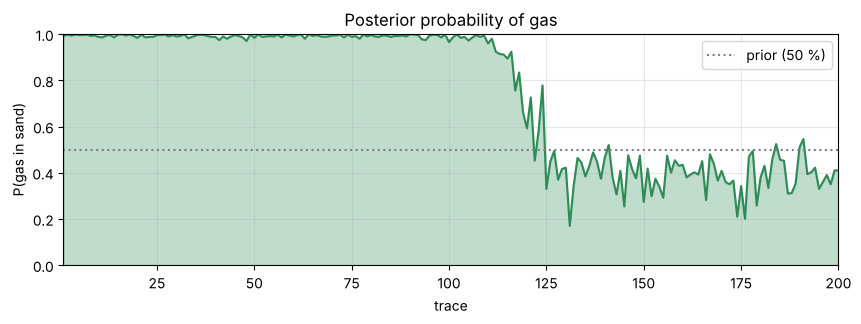

In [10]:
p_gas = np.array([r.fluid_probabilities()[1, 3] for r in results])
plt.figure(figsize=(10, 3))
plt.plot(x, p_gas, color="seagreen")
plt.fill_between(x, 0, p_gas, color="seagreen", alpha=0.3)
plt.axhline(0.5, color="gray", ls=":", label="prior (50 %)")
plt.ylim(0, 1); plt.xlim(1, n_traces); plt.xlabel("trace"); plt.ylabel("P(gas in sand)")
plt.title("Posterior probability of gas"); plt.legend(); plt.grid(alpha=0.3); plt.show()

* Where the sand is thick, the prior's 50/50 becomes **about 100 % gas**: a
  brine sand would be nearly invisible, but we see a bright spot.
* As the sand thins below about 10 ms (traces ~110-129) its echo weakens, and
  the gas probability drops: a very thin bright gas sand and a thicker dim
  brine sand start to look alike.
* Where the sand is absent there is nothing to measure and the answer is near
  the prior, slightly *below* 50 %: if any sand were there, a gas sand would
  have shown up as an echo but a thin brine sand would not, so the small
  remaining chance of sand is more likely brine.

## Summary

* We built a gas sand wedge across 200 traces, made its seismic, and inverted
  it knowing only rough horizon picks and rock-physics trends.
* The standard QC shows the estimated impedance reproducing the true wedge and
  a residual that looks like the added noise.
* Beyond the QC, Delivery answers the geological questions directly: the sand
  thickness with its uncertainty, the **probability of pinch-out**, and the
  **probability of gas**.
* All results are in `wedge_data/results.h5`, one array per property with
  shape (traces, samples, layers). Load them with
  `pydelivery.read_results("wedge_data/results.h5")`, or summarise from the
  command line with `pydelivery summary wedge_data/results.h5 --property NG`.

To try your own variations, change the XML (e.g. the gas probability, the
noise level, the sigma of the picks) or the true model in Step 3 and re-run.
A good first experiment: set the sand velocity intercept back to 3500 m/s.
Brine sand then becomes bright and gas sand dim, and the evidence for gas
comes from the *absence* of an echo instead.